# **Case Study 2: Data Analytics End to End Project**
### ***Retail Fashion Boutique Data Sales Analytics 2025***

This comprehensive fashion retail synthetic dataset contains 2,176 real-world style records spanning seasonal collections, customer purchasing behavior, pricing strategies, and return analytics. Perfect for data science projects, machine learning models, and business intelligence dashboards focused on retail analytics and e-commerce insights.

*Source:* https://www.kaggle.com/datasets/pratyushpuri/retail-fashion-boutique-data-sales-analytics-2025

### Scenario
In a time when online shopping is part of everyday life, product returns have become increasingly common, and increasingly costly for both companies and the environment. This project analyzes purchase patterns in the fashion retail sector and identifies the main factors linked to returns, in order to generate insights and suggest improvements that help reduce their impact on the business.

### Goal
Which product characteristics (brand, category, collection, size, price, discount and rating) are most associated with returns, and what actions could help reduce them?

### Approach
1. **Python:** data collection, cleaning and exploratory data analysis (EDA)
2. **Python + SQL:** design the relational schema (brands, categories, collections and purchases tables) and load the clean data into MySQL
3. **SQL:** analytical queries to answer business questions (return rate by brand, category, collection, price, discount, size, rating and return reason)
4. **Python:** statistical analysis (chi-square hypothesis tests) to check whether the differences found in SQL are statistically significant
5. **Tableau:** final dashboard and storytelling, with insights and recommendations

# **The Dataframe**

In [115]:
# ============================================
# Libraries used in this notebook
# ============================================

# Data manipulation
import pandas as pd   # DataFrames: loading, cleaning and transforming data
import numpy as np    # Numerical operations and conditional logic (e.g. np.select)

# Visualization
import matplotlib.pyplot as plt   # Base plotting library (figures, axes, titles)
import seaborn as sns             # Statistical charts built on matplotlib (histograms, boxplots, heatmaps)

# Statistical analysis
from scipy.stats import chi2_contingency   # Chi-square test of independence (hypothesis tests)

# SQL connection (Python to MySQL)
from sqlalchemy import create_engine   # Creates the connection (engine) to the MySQL database
from sqlalchemy.engine import URL      # Builds the connection URL safely (handles special characters in the password)
import getpass                         # Asks for the password without showing it on screen

In [116]:
df = pd.read_csv("fashion_boutique_dataset.csv")
df.head()

,product_id,category,brand,season,size,color,original_price,markdown_percentage,current_price,purchase_date,stock_quantity,customer_rating,is_returned,return_reason
0,FB000001,Outerwear,Zara,Spring,XL,Red,196.01,0.0,196.01,2025-07-05,37,3.0,False,NaN
1,FB000002,Tops,Uniqlo,Winter,L,Pink,119.64,0.0,119.64,2025-08-06,2,2.5,False,NaN
2,FB000003,Accessories,Uniqlo,Winter,NaN,Black,33.80,0.0,33.80,2025-08-06,22,4.3,False,NaN
3,FB000004,Shoes,Uniqlo,Spring,XL,Black,75.36,0.0,75.36,2025-07-07,48,2.6,False,NaN
4,FB000005,Tops,Banana Republic,Winter,XL,Black,105.02,0.0,105.02,2025-08-06,10,NaN,False,NaN


In [117]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2176 entries, 0 to 2175
Data columns (total 14 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   product_id           2176 non-null   object 
 1   category             2176 non-null   object 
 2   brand                2176 non-null   object 
 3   season               2176 non-null   object 
 4   size                 1685 non-null   object 
 5   color                2176 non-null   object 
 6   original_price       2176 non-null   float64
 7   markdown_percentage  2176 non-null   float64
 8   current_price        2176 non-null   float64
 9   purchase_date        2176 non-null   object 
 10  stock_quantity       2176 non-null   int64  
 11  customer_rating      1814 non-null   float64
 12  is_returned          2176 non-null   bool   
 13  return_reason        320 non-null    object 
dtypes: bool(1), float64(4), int64(1), object(8)
memory usage: 223.3+ KB


In [118]:
# Pre-Cleaning Analysis
# Duplicates: check if each row is one unique product

print(df.duplicated().sum())
print(df['product_id'].is_unique)

0
True


In [119]:
# Pre-Cleaning Analysis
# check the null values

df.isnull().sum()

product_id                0
category                  0
brand                     0
season                    0
size                    491
color                     0
original_price            0
markdown_percentage       0
current_price             0
purchase_date             0
stock_quantity            0
customer_rating         362
is_returned               0
return_reason          1856
dtype: int64

# **Data Cleaning & Preparation**

In [120]:
# Before the data cleaning, let´s create a copy and preserve the original df just in case

retail_fashion_df=df.copy()

### Fill the null values  

In [121]:
# First, let´s fill the categories with null values: "size", "return_reason" and "customer_rating"

In [122]:
# "size" column -- object dtype

retail_fashion_df['size'] = df['size'].fillna('No Info')

In [123]:
# "return_reason" column -- object dtype
# return_reason is only empty when the item was not returned

retail_fashion_df['return_reason'] = df['return_reason'].fillna('Not Returned')

In [124]:
# "customer_rating" column -- float64 dtype
# For this column, first let´s check the values and understand the reson of this dtype

retail_fashion_df["customer_rating"].value_counts()

customer_rating
2.5    61
4.0    56
1.2    55
3.1    53
1.1    52
2.8    52
4.5    51
3.5    50
4.1    50
4.6    50
1.3    48
3.7    48
4.4    47
3.4    47
1.7    47
2.9    47
2.6    47
1.4    47
4.3    47
2.3    46
3.0    46
2.4    46
1.8    45
4.7    45
2.0    44
3.3    43
4.9    42
1.6    42
1.9    41
3.2    41
2.1    41
1.5    39
3.6    38
3.8    37
3.9    37
4.8    37
2.2    36
4.2    34
2.7    33
5.0    24
1.0    22
Name: count, dtype: int64

In [125]:
# The column has decimal values. Let´s round the rating, convert to clean text ("1" to "5") and fill missing values with "No Info"
retail_fashion_df['rating_stars'] = (
    retail_fashion_df['customer_rating']
    .round()
    .astype('Int64')
    .astype(str)
    .replace('<NA>', 'No Info')
)

In [126]:
retail_fashion_df['rating_stars'].value_counts()

rating_stars
4          495
2          488
3          409
No Info    362
1          224
5          198
Name: count, dtype: int64

In [127]:
# Now, let´s fill the null values of "rating_star" final column
retail_fashion_df['rating_stars'] = retail_fashion_df['rating_stars'].fillna('No Info')

In [128]:
retail_fashion_df.isnull().sum()

product_id               0
category                 0
brand                    0
season                   0
size                     0
color                    0
original_price           0
markdown_percentage      0
current_price            0
purchase_date            0
stock_quantity           0
customer_rating        362
is_returned              0
return_reason            0
rating_stars             0
dtype: int64

In [129]:
# Once we have the final "rating_stars" rounded column, let´s take off the "customer_rating " (original one)
retail_fashion_df = retail_fashion_df.drop(columns=['customer_rating'])

In [130]:
# Let´s check the final columns + null values final overview
retail_fashion_df.isnull().sum()

product_id             0
category               0
brand                  0
season                 0
size                   0
color                  0
original_price         0
markdown_percentage    0
current_price          0
purchase_date          0
stock_quantity         0
is_returned            0
return_reason          0
rating_stars           0
dtype: int64

### 'original_price', 'markdown_percentage' and 'current_price' relation analysis

In [131]:
# Now, let´s understand the relation between the columns 'original_price', 'markdown_percentage', 'current_price'
# First, let´s check the the mix / max values and some other details of all these three columns

retail_fashion_df[['original_price', 'markdown_percentage', 'current_price']].describe()

,original_price,markdown_percentage,current_price
count,2176.000000,2176.000000,2176.000000
mean,97.200340,12.144715,85.499596
std,51.637345,18.417786,50.091354
min,15.140000,0.000000,7.290000
25%,57.872500,0.000000,46.845000
50%,88.600000,0.000000,74.885000
75%,127.630000,22.425000,112.865000
max,249.980000,59.900000,249.980000


In [132]:
# Normally, 'current_price' should be equal to 'original_price' minus the discount (markdown_percentage). 
# It is worth verifying whether this calculation matches correctly. If 'price_diff' is close to zero for most rows, the logic is consistent. 
# If there are many values significantly different from zero, it may indicate data inconsistencies that are worth investigating before proceeding 
    
retail_fashion_df['expected_price'] = retail_fashion_df['original_price'] * (1 - retail_fashion_df['markdown_percentage']/100)
retail_fashion_df['price_diff'] = retail_fashion_df['current_price'] - retail_fashion_df['expected_price']
retail_fashion_df['price_diff'].describe()

count    2176.000000
mean       -0.000013
std         0.001829
min        -0.005000
25%         0.000000
50%         0.000000
75%         0.000000
max         0.005000
Name: price_diff, dtype: float64

In [133]:
# The results confirm that the relationship is consistent. 
# 'price_diff' is effectively zero across almost all rows, indicating that current_price = original_price × (1 − markdown_percentage/100). 
# Small differences (±0.005) are due only to normal price rounding. 
# Since these three variables are mathematically dependent, keeping all of them adds little value. 
# Therefore, we will retain two continuous features ('final_price', 'markdown_percentage') for calculations and correlations, and two 
# binned features ('price_range, discount_range') for clearer visualizations and groupby analysis in the dashboard.

In [134]:
retail_fashion_df.head(3)

,product_id,category,brand,season,size,color,original_price,markdown_percentage,current_price,purchase_date,stock_quantity,is_returned,return_reason,rating_stars,expected_price,price_diff
0,FB000001,Outerwear,Zara,Spring,XL,Red,196.01,0.0,196.01,2025-07-05,37,False,Not Returned,3,196.01,0.0
1,FB000002,Tops,Uniqlo,Winter,L,Pink,119.64,0.0,119.64,2025-08-06,2,False,Not Returned,2,119.64,0.0
2,FB000003,Accessories,Uniqlo,Winter,No Info,Black,33.80,0.0,33.80,2025-08-06,22,False,Not Returned,4,33.80,0.0


In [135]:
# Once we already have the previous relationshio analysis result, let´s take off the support columns
retail_fashion_df = retail_fashion_df.drop(columns=['expected_price', 'price_diff'])

# And let´s rename "current_price" to "final_price"
retail_fashion_df = retail_fashion_df.rename(columns={'current_price': 'final_price'})

In [136]:
retail_fashion_df.head(3)

,product_id,category,brand,season,size,color,original_price,markdown_percentage,final_price,purchase_date,stock_quantity,is_returned,return_reason,rating_stars
0,FB000001,Outerwear,Zara,Spring,XL,Red,196.01,0.0,196.01,2025-07-05,37,False,Not Returned,3
1,FB000002,Tops,Uniqlo,Winter,L,Pink,119.64,0.0,119.64,2025-08-06,2,False,Not Returned,2
2,FB000003,Accessories,Uniqlo,Winter,No Info,Black,33.80,0.0,33.80,2025-08-06,22,False,Not Returned,4


In [137]:
# Beyond the continous columns, the idea is to create binned versions for 'final_price' and'markdown_percentage' columns
# The binned versions will help with visualizations and groupby analysis
# Let´s check the distribution first to confirm the bin limits make sense

retail_fashion_df[['final_price', 'markdown_percentage']].describe()

,final_price,markdown_percentage
count,2176.000000,2176.000000
mean,85.499596,12.144715
std,50.091354,18.417786
min,7.290000,0.000000
25%,46.845000,0.000000
50%,74.885000,0.000000
75%,112.865000,22.425000
max,249.980000,59.900000


In [138]:
# final_price: keep the continuous column and add a binned version
retail_fashion_df['price_range'] = pd.cut(
    retail_fashion_df['final_price'],
    bins=[0, 25, 50, 100, 200, float('inf')],
    labels=['0-25€', '25-50€', '50-100€', '100-200€', '200€+']
)

# markdown_percentage: keep the continuous column and add a binned version
# (-0.01 ensures that exact 0 values fall into "No discount")
retail_fashion_df['discount_range'] = pd.cut(
    retail_fashion_df['markdown_percentage'],
    bins=[-0.01, 0, 10, 25, 50, 100],
    labels=['No discount', '1-10%', '11-25%', '26-50%', '50%+']
)

# Drop original_price: it is redundant (can be recalculated from final_price and markdown_percentage)
# and not relevant for the return analysis
retail_fashion_df = retail_fashion_df.drop(columns=['original_price'])

In [139]:
# Check the result: continuous columns + binned versions, without original_price
retail_fashion_df[['final_price', 'price_range', 'markdown_percentage', 'discount_range']].head()

,final_price,price_range,markdown_percentage,discount_range
0,196.01,100-200€,0.0,No discount
1,119.64,100-200€,0.0,No discount
2,33.80,25-50€,0.0,No discount
3,75.36,50-100€,0.0,No discount
4,105.02,100-200€,0.0,No discount


In [140]:
# Check how many rows fall into each bin (to confirm none is empty or too dominant)
print(retail_fashion_df['price_range'].value_counts().sort_index())
print(retail_fashion_df['discount_range'].value_counts().sort_index())

# Check that no row was left without a bin (should be 0)
print(retail_fashion_df[['price_range', 'discount_range']].isna().sum())

price_range
0-25€       130
25-50€      483
50-100€     852
100-200€    643
200€+        68
Name: count, dtype: int64
discount_range
No discount    1298
1-10%           147
11-25%          226
26-50%          359
50%+            146
Name: count, dtype: int64
price_range       0
discount_range    0
dtype: int64


### "purchase_date" column adjustments

In [141]:
# Let´s adjust "purchase_date" column
# First, let´s check the current dtype and how the dates look

print(retail_fashion_df['purchase_date'].dtype)
retail_fashion_df['purchase_date'].head(10)

object


0    2025-07-05
1    2025-08-06
2    2025-08-06
3    2025-07-07
4    2025-08-06
5    2025-08-06
6    2024-10-29
7    2025-08-06
8    2025-03-24
9    2025-08-06
Name: purchase_date, dtype: object

In [142]:
# Convert purchase_date from text to datetime (format: YYYY-MM-DD)
retail_fashion_df['purchase_date'] = pd.to_datetime(retail_fashion_df['purchase_date'], format='%Y-%m-%d')

In [143]:
# Now, let´s check the purchase data concentration date 
print(retail_fashion_df['purchase_date'].value_counts().head(5))

purchase_date
2025-08-06    1641
2025-04-25       6
2024-09-06       5
2024-09-28       5
2025-05-09       5
Name: count, dtype: int64


In [144]:
# Many rows share the same date, which can bias month/sale_period
# So, which collections have real dates vs. the default date? Let´s consider 2025-08-06 as parameter.

print(pd.crosstab(retail_fashion_df['season'], retail_fashion_df['purchase_date'] == '2025-08-06'))

purchase_date  False  True 
season                     
Fall               0    544
Spring           535      0
Summer             0    575
Winter             0    522


In [145]:
# - 1641 of 2176 rows (75%) share the same date (2025-08-06)
# - This date appears only in the Fall, Summer and Winter collections; only Spring (535 rows) has varied dates
# - The date is confounded with the collection, probably a default value from the synthetic data generator
# - This means that only 535 rows have real dates, all of them in the Spring collection
# - Decision: a 'sale_period' column is not reliable with these dates, so it was removed; time analysis is limited to rows with real dates

### Last adjustments

In [146]:
# Rename 'season' to 'collection' (it represents the product collection, not the purchase season)

retail_fashion_df = retail_fashion_df.rename(columns={'season': 'collection'})

In [147]:
# Let´s take a final look on "size" column
# Are the missing sizes concentrated in specific categories?

print(pd.crosstab(retail_fashion_df['category'], retail_fashion_df['size'] == 'No Info'))

size         False  True 
category                 
Accessories      0    402
Bottoms        371     21
Dresses        300     17
Outerwear      322     12
Shoes          350     22
Tops           342     17


In [148]:
# Accessories have no size by nature: not missing data
retail_fashion_df.loc[retail_fashion_df['category'] == 'Accessories', 'size'] = 'Not applicable'

In [149]:
# What does 'size' look like now?
print(retail_fashion_df['size'].value_counts(dropna=False))

# Size distribution by category (this shows if sizes are missing for specific categories)
print(pd.crosstab(retail_fashion_df['category'], retail_fashion_df['size']))

size
Not applicable    402
XS                301
S                 294
XL                283
XXL               279
L                 273
M                 255
No Info            89
Name: count, dtype: int64
size          L   M  No Info  Not applicable   S  XL  XS  XXL
category                                                     
Accessories   0   0        0             402   0   0   0    0
Bottoms      62  57       21               0  58  53  69   72
Dresses      41  43       17               0  52  71  47   46
Outerwear    55  51       12               0  62  44  60   50
Shoes        55  60       22               0  61  57  67   50
Tops         60  44       17               0  61  58  58   61


In [150]:
# Take an overview to check if there is inconsistent text values (typos, extra spaces, different casing)
for col in ['category', 'brand', 'collection', 'size', 'color', 'return_reason']:
    print(col, retail_fashion_df[col].unique())

category ['Outerwear' 'Tops' 'Accessories' 'Shoes' 'Bottoms' 'Dresses']
brand ['Zara' 'Uniqlo' 'Banana Republic' 'Mango' 'H&M' 'Ann Taylor' 'Gap'
 'Forever21']
collection ['Spring' 'Winter' 'Fall' 'Summer']
size ['XL' 'L' 'Not applicable' 'S' 'XXL' 'XS' 'M' 'No Info']
color ['Red' 'Pink' 'Black' 'White' 'Gray' 'Blue' 'Green' 'Beige' 'Navy'
 'Purple' 'Brown']
return_reason ['Not Returned' 'Color Mismatch' 'Size Issue' 'Damaged' 'Quality Issue'
 'Changed Mind' 'Wrong Item']


### Final dataset overview

In [151]:
retail_fashion_df.sample(5)

,product_id,category,brand,collection,size,color,markdown_percentage,final_price,purchase_date,stock_quantity,is_returned,return_reason,rating_stars,price_range,discount_range
1772,FB001773,Accessories,Uniqlo,Fall,Not applicable,Navy,40.8,27.69,2025-08-06,25,False,Not Returned,3,25-50€,26-50%
1470,FB001471,Shoes,Banana Republic,Winter,XXL,Pink,20.3,95.57,2025-08-06,15,False,Not Returned,4,50-100€,11-25%
552,FB000553,Dresses,Zara,Spring,L,Beige,0.0,168.92,2025-07-14,11,False,Not Returned,4,100-200€,No discount
1843,FB001844,Dresses,Mango,Fall,S,Pink,0.0,169.64,2025-08-06,5,False,Not Returned,2,100-200€,No discount
1806,FB001807,Accessories,Zara,Summer,Not applicable,Black,0.0,73.75,2025-08-06,23,False,Not Returned,4,50-100€,No discount


In [152]:
# Check nulls and dtypes one last time
retail_fashion_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2176 entries, 0 to 2175
Data columns (total 15 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   product_id           2176 non-null   object        
 1   category             2176 non-null   object        
 2   brand                2176 non-null   object        
 3   collection           2176 non-null   object        
 4   size                 2176 non-null   object        
 5   color                2176 non-null   object        
 6   markdown_percentage  2176 non-null   float64       
 7   final_price          2176 non-null   float64       
 8   purchase_date        2176 non-null   datetime64[ns]
 9   stock_quantity       2176 non-null   int64         
 10  is_returned          2176 non-null   bool          
 11  return_reason        2176 non-null   object        
 12  rating_stars         2176 non-null   object        
 13  price_range          2176 non-nul

# **Exploratory Data Analysis (EDA)**

In [153]:
# Let´s create a copy to preserve the previous df
final_rf_df = retail_fashion_df.copy()

In [154]:
# Size of the dataset (rows, columns)
print(final_rf_df.shape)

(2176, 15)


In [155]:
# Overall return rate: this is the baseline for every comparison
print(f"Overall return rate: {final_rf_df['is_returned'].mean():.1%}")

Overall return rate: 14.7%


In [156]:
# Summary of the numeric columns
final_rf_df[['final_price', 'markdown_percentage', 'stock_quantity']].describe().round(2)

,final_price,markdown_percentage,stock_quantity
count,2176.00,2176.00,2176.00
mean,85.50,12.14,24.94
std,50.09,18.42,14.45
min,7.29,0.00,0.00
25%,46.84,0.00,13.00
50%,74.88,0.00,25.00
75%,112.86,22.42,37.00
max,249.98,59.90,50.00


### ***Numerical Columns Analysis***

Let's analyze the numerical columns `final_price`, `markdown_percentage` and `stock_quantity` and visualize them with summary statistics, histograms, boxplots and a correlation heatmap.

In [203]:
# Earth palette (light -> dark)
EARTH = {
    "cream":      "#F4E8DC",
    "sand":       "#E4C3AA",
    "clay":       "#CD9A7C",
    "terracotta": "#B5654A",
    "rust":       "#9A4F36",
    "brown":      "#7A3E2B",
    "taupe":      "#8C7B6E",
    "stone":      "#B8A99A",
    "olive":      "#8A8A6B",   # accent to break the monotony
    "charcoal":   "#3B3330",
}

# Color for each numeric column
colors = [EARTH["terracotta"], EARTH["clay"], EARTH["taupe"]]

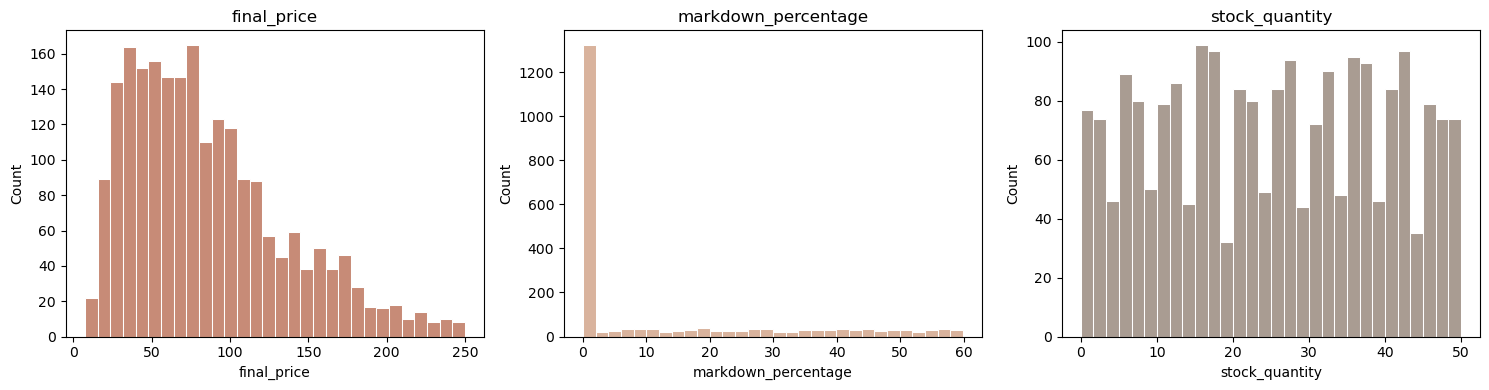

In [204]:
# HISTOGRAMS

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, col, color in zip(axes, ['final_price', 'markdown_percentage', 'stock_quantity'], colors):
    sns.histplot(final_rf_df[col], bins=30, ax=ax, color=color, edgecolor='white')
    ax.set_title(col)

plt.tight_layout()
plt.show()

### Histogram Insights

#### *final_price*
- Most purchases are concentrated between about €25 and €100, with a peak around €30-80.
- The distribution then declines gradually, with a long right "tail" up to €250. This tail pulls the mean (€85.50) above the median (€74.88).
- This is a typical shape for fashion prices: many cheap or mid-priced items, few expensive ones.

#### *markdown_percentage*
- The 0% bar has about 1,300 purchases. All the other ranges have only 20 to 40 each.
- Between 1% and 60%, discounts are spread almost uniformly, with no "usual" discount (such as 20% or 30%).
- This confirms what we saw: the variable is, in practice, two groups: no discount (60%) and with discount (40%).
- For this reason, comparing "with discount vs. no discount" is more informative than using the mean.

#### *stock_quantity*
- The bars have similar heights across the whole range from 0 to 50, with no peak or trend. The variations between bars are just noise.
- This is the pattern of randomly drawn numbers, another sign that the dataset is synthetic. This column is not expected to explain much.

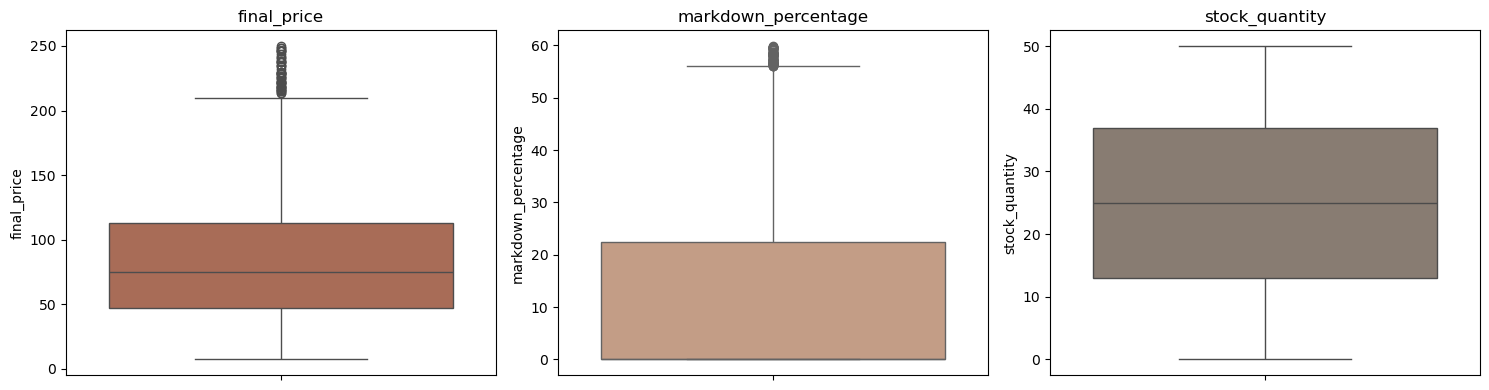

In [205]:
# BOXPLOT

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, col, color in zip(axes, ['final_price', 'markdown_percentage', 'stock_quantity'], colors):
    sns.boxplot(y=final_rf_df[col], ax=ax, color=color)
    ax.set_title(col)

plt.tight_layout()
plt.show()

### Boxplot Insights

#### *final_price*
- There are outliers between about €210 and €250, which is the same long right tail seen in the histogram. 
- They are plausible fashion prices (e.g. outerwear), not errors, so they were kept.
    
#### *markdown_percentage*
- The box starts at 0 and the median is 0, because most purchases have no discount. 
- The points above ~56% are valid high discounts, not errors. 
- This variable is better analysed as "with discount vs. no discount" or by discount range.
    
#### *stock_quantity*
- No outliers. The values are spread evenly between 0 and 50, which is typical of synthetic data.

*Decision: no outliers were removed, since none of them are data errors.*

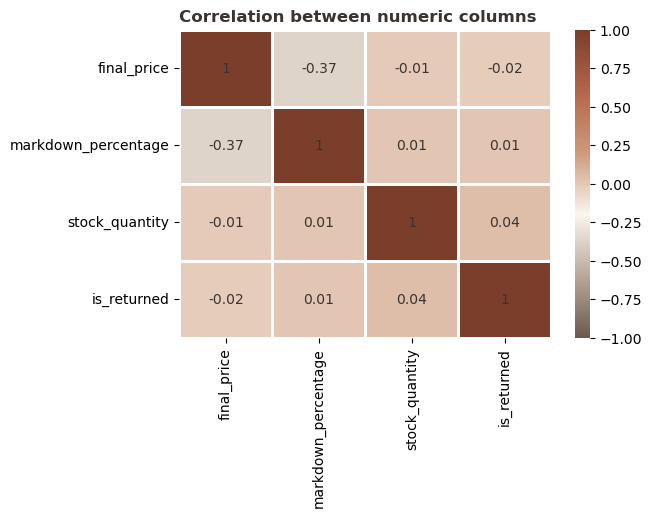

In [209]:
# HEATMAP
from matplotlib.colors import LinearSegmentedColormap

# is_returned is True/False, so convert it to 0/1 to include it in the correlation
corr_df = final_rf_df[['final_price', 'markdown_percentage', 'stock_quantity']].copy()
corr_df['is_returned'] = final_rf_df['is_returned'].astype(int)

# Earth diverging palette: taupe (negative) -> cream (zero) -> terracotta (positive)
earth_div = LinearSegmentedColormap.from_list(
    "earth_div", ["#6B5B4F", "#B8A99A", "#FAF5EF", "#CD9A7C", "#B5654A", "#7A3E2B"]
)

# Draw the heatmap (center=0 keeps cream exactly at zero correlation)
plt.figure(figsize=(6, 4))
sns.heatmap(corr_df.corr().round(2), annot=True, cmap=earth_div,
            vmin=-1, vmax=1, center=0,
            linewidths=1, linecolor="white",           # white lines between cells
            annot_kws={"color": "#3B3330"})            # dark brown numbers

# Title in the project style
plt.title('Correlation between numeric columns', loc="left",
          fontweight="bold", color="#3B3330")
plt.show()

### Correlation Insights

- **final_price vs. markdown_percentage (-0.37):** the only visible relationship. It is mechanical, since the final price already includes the discount, so it is not a purchase behavior insight.
- **Relationship with is_returned:** all correlations are close to zero (final_price -0.02, markdown_percentage 0.01, stock_quantity 0.04). None of the numeric variables explains returns on its own.
- **Limitation:** correlation only measures linear relationships. Differences between groups (e.g. by category, brand or discount range) can still exist, so they will be explored in SQL and tested statistically in Python.
    

### ***Categorical Columns Analysis (Overview)***

Plotted: ['category', 'brand', 'season', 'size', 'color', 'return_reason']
Skipped (more than 12 categories): ['product_id', 'purchase_date']


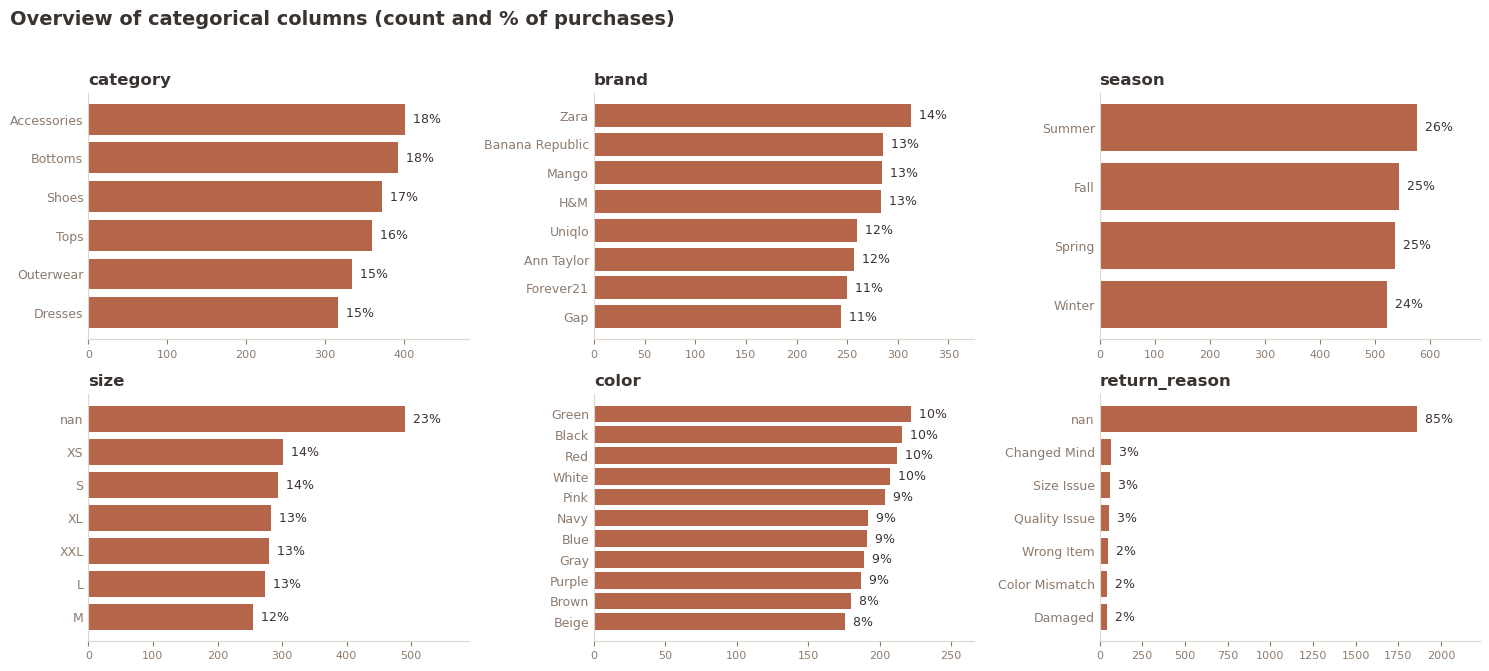

In [193]:
TERRACOTTA, TEXT, MUTED = "#B5654A", "#3B3330", "#8C7B6E"

# 1. Pick the categorical columns (text columns with up to 12 categories)
all_cat = df.select_dtypes(include=["object", "category", "string"]).columns
cat_cols = [c for c in all_cat if df[c].nunique() <= 12]
print("Plotted:", cat_cols)
print("Skipped (more than 12 categories):", [c for c in all_cat if c not in cat_cols])

# 2. Grid of charts (3 per row)
ncols = 3
nrows = int(np.ceil(len(cat_cols) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(15, 3.4 * nrows))
axes = np.atleast_1d(axes).ravel()

for ax, col in zip(axes, cat_cols):
    counts = df[col].value_counts(dropna=False).sort_values()
    pct = counts / counts.sum() * 100
    ax.barh(counts.index.astype(str), counts.values, color=TERRACOTTA)
    for y, (v, p) in enumerate(zip(counts.values, pct.values)):
        ax.text(v, y, f"  {p:.0f}%", va="center", fontsize=9, color=TEXT)
    ax.set_title(col, loc="left", fontsize=12, fontweight="bold", color=TEXT)
    ax.set_xlim(0, counts.max() * 1.2)
    ax.tick_params(axis="y", labelsize=9, colors=MUTED, length=0)
    ax.tick_params(axis="x", labelsize=8, colors=MUTED)
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
    for side in ["left", "bottom"]:
        ax.spines[side].set_color("#E0D6CA")

for ax in axes[len(cat_cols):]:   # hide empty panels
    ax.axis("off")

fig.suptitle("Overview of categorical columns (count and % of purchases)",
             x=0.01, ha="left", fontsize=14, fontweight="bold", color=TEXT)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

**Quick takeaways**

- **Balanced distribution:** purchases are spread fairly evenly across categories (15-18% each), brands (11-14% each) and seasons (24-26% each). No single category, brand or season dominates the dataset.
- **Size:** the sizes (XS to XXL) each represent 12-14% of purchases, and `nan` (missing size) accounts for 23%, the largest single group.
- **Color:** also evenly distributed, with each color representing 8-10% of purchases.
- **Return reason:** `nan` accounts for 85% of rows, i.e. purchases that were **not returned**. The remaining 15% (the returned items) is split across six reasons (Changed Mind, Size Issue, Quality Issue, Wrong Item, Color Mismatch, Damaged), each at 2-3% of all purchases.
- **Skipped columns:** `product_id` and `purchase_date` have more than 12 unique values, so they are not shown here.

Since no category dominates, differences in return rates are better explored with rates per group rather than raw counts. **All categorical analyses are performed in SQL, and the corresponding visualizations are built in Tableau.**

**All categorical analyses are performed in SQL, and the corresponding visualizations are built in Tableau.**

# **Business Analysis (From Python to SQL)**

In [171]:
# Business metrics analysis will be done in SQL
# First, let´s create a copy to preserve the previous df

retail_fashion = final_rf_df.copy()

### Database Modeling | Tables

To prepare the SQL database, we normalize the cleaned dataset into multiple relational tables.
The database consists of:

- Brands
- Categories
- Collections
- Purchases (main table)

This structure reduces redundancy and enables efficient SQL queries using primary and foreign keys

In [162]:
# 1- TABLE brands
brands_df = (
    final_rf_df[["brand"]]
    .drop_duplicates()
    .sort_values("brand")
    .reset_index(drop=True)
)
brands_df["brand_id"] = brands_df.index + 1
brands_df = brands_df[["brand_id", "brand"]]
brands_df

,brand_id,brand
0,1,Ann Taylor
1,2,Banana Republic
2,3,Forever21
3,4,Gap
4,5,H&M
5,6,Mango
6,7,Uniqlo
7,8,Zara


In [163]:
# 2- TABLE categories
categories_df = (
    final_rf_df[["category"]]
    .drop_duplicates()
    .sort_values("category")
    .reset_index(drop=True)
)
categories_df["category_id"] = categories_df.index + 1
categories_df = categories_df[["category_id", "category"]]
categories_df

,category_id,category
0,1,Accessories
1,2,Bottoms
2,3,Dresses
3,4,Outerwear
4,5,Shoes
5,6,Tops


In [164]:
# 3- TABLE collections
collections_df = (
    final_rf_df[["collection"]]
    .drop_duplicates()
    .sort_values("collection")
    .reset_index(drop=True)
)
collections_df["collection_id"] = collections_df.index + 1
collections_df = collections_df[["collection_id", "collection"]]
collections_df

,collection_id,collection
0,1,Fall
1,2,Spring
2,3,Summer
3,4,Winter


In [165]:
# 4- TABLE purchases (names replaced by ids)
purchases_df = (
    final_rf_df
    .merge(brands_df, on="brand", how="left")
    .merge(categories_df, on="category", how="left")
    .merge(collections_df, on="collection", how="left")
    .drop(columns=["brand", "category", "collection"])
)

# Binned columns to text so MySQL accepts them
purchases_df["price_range"] = purchases_df["price_range"].astype(str)
purchases_df["discount_range"] = purchases_df["discount_range"].astype(str)

print(purchases_df.shape)  # must be (2176, 15)

(2176, 15)


In [166]:
print("brands:", brands_df.shape)
print("categories:", categories_df.shape)
print("collections:", collections_df.shape)
print("purchases:", purchases_df.shape)

brands: (8, 2)
categories: (6, 2)
collections: (4, 2)
purchases: (2176, 15)


### Export cleaned tables from Python to SQL Workbench

In [180]:
# Step 0 -- SQL password request, connection string and database (or bd)

password = getpass.getpass("analyst password: ")
print(len(password) > 0)  # must print True

url = URL.create(
    "mysql+mysqlconnector",
    username="analyst",
    password=password,
    host="localhost",
    port=3306,
    database="retail_fashion",
)

# Step 1 -- create_engine
engine = create_engine(url)

# Step 2 -- engine_connect
with engine.connect() as conn:
    print("Connected")

analyst password:  ········


True
Connected


# **SQL Analysis: Business Insights**

Overall return rate: **14.7%** (320 returns out of 2,176 purchases). All comparisons below use this value as the baseline.

### QUERY 1: Brand insights
*Purchases, returns and return rate per brand*
- Purchases are evenly distributed across brands (244 to 313 each), with no dominant brand.
- **Ann Taylor** has the highest return rate (19.8%), about 5 points above the overall rate.
- **Mango** has the lowest return rate (11.3%).
- The other brands stay close to the overall rate (12.7% to 16.5%).

### QUERY 2: Category insights
*Purchases, returns and return rate per category*
- Purchases are spread across categories (317 to 402 each); Accessories has the highest volume.
- Return rates range from 12.8% (Tops) to 16.2% (Outerwear), a narrow gap of about 3.4 points.
- Outerwear and Bottoms are slightly above the overall rate; Tops and Accessories are below.

### QUERY 3: Collection insights
*Purchases, returns and return rate per collection*
- Purchases are evenly spread across collections (522 to 575 each).
- Return rates range from 11.9% (Fall) to 17.4% (Summer), the widest gap among the product variables.
- Summer and Winter are above the overall rate; Spring and Fall are below.
- Note: `collection` refers to the product collection, not the season of purchase.

### QUERY 4: Return reasons by category insights
*Return reasons by category (share within each category's returns)*
- Each category has only 46 to 62 returns split across 6 reasons (3 to 16 cases per cell), so these are exploratory hints, not conclusions.
- Changed Mind is the top reason in Bottoms, Outerwear and Shoes, consistent with the overall ranking.
- Dresses stands out for Quality Issue (25.5%, 12 cases) vs. 17.2% overall, which could be explored from a textile perspective (fabric, finishing).
- Accessories has Color Mismatch on top (23.6%), but also 20% of Size Issue, which makes no sense for products without size: another sign of synthetic data.
- No reason is clearly tied to a specific category.

### QUERY 5: Return reasons by collection insights
*Return reasons by collection (share within each collection's returns)*
- Summer has the most returns (100) and its reasons are evenly spread; it has the highest Size Issue count of any collection (22 cases).
- Fall has the lowest return rate, and almost a third of its returns are Changed Mind (30.8%).
- Spring stands out for Quality Issue (27.8%, 20 cases) vs. 17.2% overall.
- Each collection has 65 to 100 returns split across 6 reasons, so these are exploratory hints, not conclusions.

### QUERY 6: Brands vs. overall return rate insights
*Difference between each brand's return rate and the overall rate*
- Only Ann Taylor (+5.1 pp) and Mango (-3.4 pp) are clearly away from the overall rate; all other brands are within 2 points.
- With 244 to 313 purchases per brand, part of this variation may be chance. This is checked with a chi-square test in the Hypothesis Test section.

### QUERY 7: Price range insights
*Purchases, returns and return rate per price range*
- Return rates range from 13.2% (100-200€) to 17.6% (200€+), with no consistent trend as price increases.
- The 200€+ range has the highest rate but only 68 purchases, so the difference may be noise.
- This is consistent with the near-zero correlation between `final_price` and `is_returned` (-0.02).

### QUERY 8 and 9: Discount insights
*Return rate per discount range, and with discount vs. no discount*
- 26-50% (17.0%) and 11-25% (16.8%) are above the overall rate; 1-10% (10.9%) is the lowest.
- There is no consistent trend: the rate does not keep rising with the discount (50%+ drops to 13.0%).
- The 1-10% and 50%+ ranges have only ~147 purchases each, so their rates may be noise.
- **With discount vs. no discount:** 15.3% vs. 14.3%, a difference of about 1 point.

### QUERY 10: Size insights
*Purchases, returns and return rate per size (products with size only)*
- Analysis restricted to products with a size (Accessories and missing sizes excluded).
- Return rates range from 13.3% (M, XXL) to 17.6% (L), with no logical pattern (e.g. extreme sizes are not consistently higher).

### QUERY 11: Rating insights
*Purchases, returns and return rate per rating (ratings given only)*
- Analysis restricted to purchases with a rating.
- Return rates range from 11.2% (1 star) to 17.6% (3 stars), with no consistent trend as the rating increases.
- A 1-star rating having the lowest return rate is counterintuitive and suggests the data is synthetic.
- Rating may be given after the return, so only association (not causality) can be discussed.

### QUERY 12: Return reasons insights
*Return reasons: number and share of returns*
- Changed Mind is the most frequent reason (21.3%), followed by Size Issue (18.8%) and Quality Issue (17.2%).
- The distribution is fairly flat (13.8% to 21.3%): no single reason dominates.
- Grouping the reasons: customer/product-fit related (Changed Mind, Size Issue, Color Mismatch) ≈ 54%; operational or quality failures (Quality Issue, Wrong Item, Damaged) ≈ 46%.
- The second group is potentially preventable by the company (warehouse, shipping and production quality).
- Size Issue (18.8%) is well below the 40-50% usually reported for fashion, another sign that the data is synthetic.

### SQL summary
- Variation in return rates is small across most variables; **collection** and **brand** show the widest gaps.
- Price, discount, size and rating show no consistent trend.
- Return reasons are spread out, and almost half come from operational or quality failures.
- These patterns are tested statistically in the next section.

# **Hypothesis Test**

All hypotheses below were raised from the SQL analysis.   
Each one is tested with a chi-square test of independence at a 5% significance level (p < 0.05 means H0 is rejected).

*p-value < 0.05: statistically significant difference (unlikely to be just by chance).*   
*p-value ≥ 0.05: there isn't enough evidence of a difference.*

**Hypothesis 1: brand**
- H0: return rate does not differ between brands (brand and returns are independent).
- H1: return rate differs between brands.

**Hypothesis 2: category**
- H0: return rate does not differ between categories.
- H1: return rate differs between categories.

**Hypothesis 3: collection**
- H0: return rate does not differ between collections.
- H1: return rate differs between collections.

**Hypothesis 4: price range**
- H0: price range is not associated with returns.
- H1: price range is associated with returns.

**Hypothesis 5: discount**
- H0: having a discount is not associated with returns.
- H1: having a discount is associated with returns.

**Hypothesis 6: size**
- H0: size is not associated with returns.
- H1: size is associated with returns.
- Only products with a size (Accessories and missing sizes excluded).

**Hypothesis 7: rating**
- H0: rating is not associated with returns.
- H1: rating is associated with returns.
- Only purchases with a rating (missing ratings excluded). Association only, not causality.


In [173]:
# H1-H7: chi-square test of independence between each variable and is_returned
# For each hypothesis, a contingency table (ct) counts returned vs. not returned purchases per group
# 'sized' and 'rated' exclude rows with missing values (same filters used in SQL)
# p-value < 0.05: significant association | p-value >= 0.05: not significant
# Note: H5 is tested here by discount_range; the with vs. without discount test is in the next cell

sized = final_rf_df[~final_rf_df['size'].isin(['Not applicable', 'No Info'])]
rated = final_rf_df[final_rf_df['rating_stars'] != 'No Info']

tests = [
    ("H1 brand",          final_rf_df, 'brand'),
    ("H2 category",       final_rf_df, 'category'),
    ("H3 collection",     final_rf_df, 'collection'),
    ("H4 price_range",    final_rf_df, 'price_range'),
    ("H5 discount_range", final_rf_df, 'discount_range'),
    ("H6 size",           sized,       'size'),
    ("H7 rating_stars",   rated,       'rating_stars'),
]

for name, data, col in tests:
    ct = pd.crosstab(data[col], data['is_returned'])
    chi2, p, dof, expected = chi2_contingency(ct)
    print(f"{name}: p-value = {p:.3f}  ->  {'significant' if p < 0.05 else 'not significant'}")

H1 brand: p-value = 0.178  ->  not significant
H2 category: p-value = 0.798  ->  not significant
H3 collection: p-value = 0.049  ->  significant
H4 price_range: p-value = 0.741  ->  not significant
H5 discount_range: p-value = 0.344  ->  not significant
H6 size: p-value = 0.642  ->  not significant
H7 rating_stars: p-value = 0.209  ->  not significant


In [174]:
# H5 (with vs. without discount): the hypothesis is about having a discount,
# so this is the test that answers it. The discount_range test above is a complement.

has_discount = final_rf_df['markdown_percentage'] > 0
ct = pd.crosstab(has_discount, final_rf_df['is_returned'])
print(f"H5 has_discount: p-value = {chi2_contingency(ct)[1]:.3f}")

H5 has_discount: p-value = 0.589


In [175]:
# H3 was the only significant result (p = 0.049), so we check where the difference comes from
# Return rate = mean of is_returned (True = 1, False = 0) in each collection
# Summer has the highest return rate and Fall the lowest, matching the SQL analysis
# Note: collection is the product collection, not the season of purchase

final_rf_df.groupby('collection')['is_returned'].mean().round(3).sort_values(ascending=False)

collection
Summer    0.174
Winter    0.159
Spring    0.135
Fall      0.119
Name: is_returned, dtype: float64

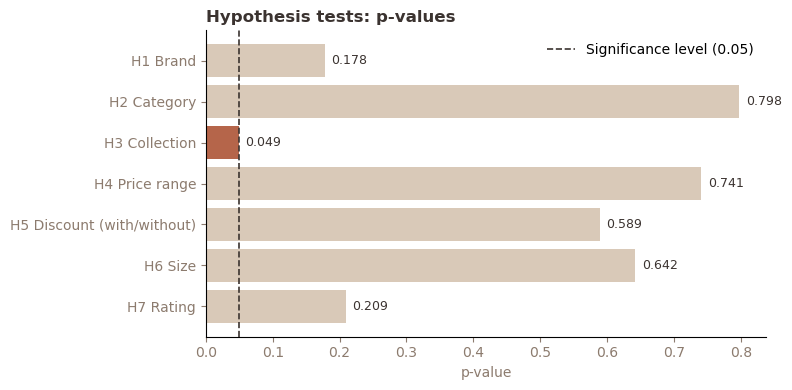

In [211]:
# Visualize the p-values of all hypothesis tests
results = pd.DataFrame({
    'hypothesis': ['H1 Brand', 'H2 Category', 'H3 Collection', 'H4 Price range',
                   'H5 Discount (with/without)', 'H6 Size', 'H7 Rating'],
    'p_value': [0.178, 0.798, 0.049, 0.741, 0.589, 0.642, 0.209]
})

# Earth palette (same as the other charts)
TERRACOTTA, SAND, TEXT, MUTED = "#B5654A", "#D9C9B8", "#3B3330", "#8C7B6E"

# Color: highlight the significant result in terracotta, the others in sand
colors = [TERRACOTTA if p < 0.05 else SAND for p in results['p_value']]

# Draw the bars
plt.figure(figsize=(8, 4))
plt.barh(results['hypothesis'], results['p_value'], color=colors)

# Significance line (alpha = 0.05)
plt.axvline(0.05, color=TEXT, linestyle='--', linewidth=1.2,
            label='Significance level (0.05)')

# p-value label at the end of each bar
for i, p in enumerate(results['p_value']):
    plt.text(p + 0.01, i, f"{p:.3f}", va='center', fontsize=9, color=TEXT)

# Layout and style
plt.gca().invert_yaxis()
plt.xlabel('p-value', color=MUTED)
plt.title('Hypothesis tests: p-values', loc='left', fontweight='bold', color=TEXT)
plt.tick_params(colors=MUTED)
sns.despine()

# Legend and display
plt.legend(frameon=False)
plt.tight_layout()
plt.show()

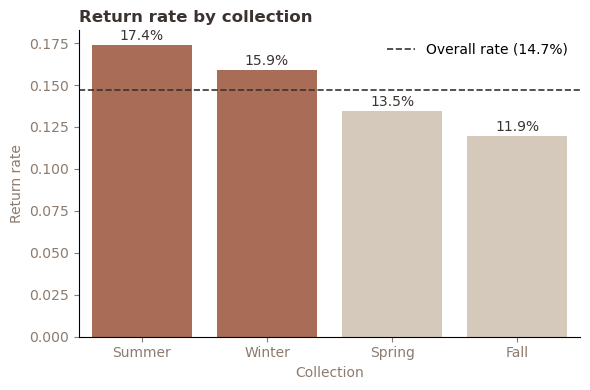

In [212]:
# Return rate by collection, compared with the overall rate
rate = final_rf_df.groupby('collection')['is_returned'].mean().sort_values(ascending=False)
overall = final_rf_df['is_returned'].mean()

# Earth palette (same as the other charts)
TERRACOTTA, SAND, TEXT, MUTED = "#B5654A", "#D9C9B8", "#3B3330", "#8C7B6E"

# Color: terracotta for collections above the overall rate, sand for the others
colors = [TERRACOTTA if v > overall else SAND for v in rate.values]

# Draw the bars
plt.figure(figsize=(6, 4))
ax = sns.barplot(x=rate.index, y=rate.values, palette=colors, hue=rate.index, legend=False)

# Overall rate reference line
ax.axhline(overall, color=TEXT, linestyle='--', linewidth=1.2,
           label=f'Overall rate ({overall:.1%})')

# Show the value above each bar
for i, v in enumerate(rate.values):
    ax.text(i, v + 0.003, f'{v:.1%}', ha='center', color=TEXT)

# Layout and style
plt.ylabel('Return rate', color=MUTED)
plt.xlabel('Collection', color=MUTED)
plt.title('Return rate by collection', loc='left', fontweight='bold', color=TEXT)
plt.tick_params(colors=MUTED)
sns.despine()

# Legend and display
plt.legend(frameon=False)
plt.tight_layout()
plt.show()

### Hypothesis Test Results
Chi-square test of independence, 5% significance level.

| Hypothesis | Variable | p-value | Decision | Interpretation |
|---|---|---|---|---|
| H1 | Brand | 0.178 | Fail to reject H0 | No evidence that return rate differs between brands |
| H2 | Category | 0.798 | Fail to reject H0 | No evidence that return rate differs between categories |
| H3 | Collection | 0.049 | Reject H0 (borderline) | Return rate differs between collections (weak evidence) |
| H4 | Price range | 0.741 | Fail to reject H0 | No evidence of association with returns |
| H5 | Discount (with vs. without) | 0.589 | Fail to reject H0 | Having a discount is not associated with returns |
| H5 (complement) | Discount range | 0.344 | Fail to reject H0 | No association by discount level |
| H6 | Size | 0.642 | Fail to reject H0 | No evidence of association with returns |
| H7 | Rating | 0.209 | Fail to reject H0 | No evidence of association with returns |

### Return rate by collection (the only significant result)

| Collection | Return rate |
|---|---|
| Summer | 17.4% |
| Winter | 15.9% |
| Spring | 13.5% |
| Fall | 11.9% |

### Key findings
- Only **collection** shows a statistically significant association with returns (p = 0.049), and the evidence is weak: Summer has the highest return rate (17.4%) and Fall the lowest (11.9%).
- Brand, category, price range, discount, size and rating show no significant association with returns.
- Failing to reject H0 does not prove there is no relationship, only that the data does not show enough evidence.

### Limitations
- Synthetic dataset, with no customer data.
- `collection` is the product collection, not the season of purchase, so no causal claim is made.
- Rating may be given after the return, so only association (not causality) can be discussed.

# **Conclusion and Recommendations**

- **Answer to the goal:** no product characteristic (brand, category, price, discount, size or rating) is significantly associated with returns. Collection is the only weak signal (Summer 17.4% vs. Fall 11.9%).
- **Most actionable finding:** return reasons are spread out, and almost half of the returns (Quality Issue, Wrong Item, Damaged) come from operational or quality failures that the company can reduce.
- **Recommendations:**
  1. Review quality control and packing/shipping processes to reduce Quality Issue, Wrong Item and Damaged returns.
  2. Monitor the Summer collection (fit, fabrics) to understand why it returns more.
  3. Collect richer data (customer ID, real purchase dates, detailed size feedback) to find stronger drivers.
- **Limitations:** synthetic dataset, no customer data, and reliable purchase dates only for the Spring collection.

# **Export final dataframe to Tableau**

In [179]:
import os

# Copy for Tableau, so the notebook dataframe stays unchanged
tableau_df = final_rf_df.copy()

# is_returned as 1/0, so Tableau can calculate the return rate with an average
tableau_df['is_returned'] = tableau_df['is_returned'].astype(int)

# Binned columns as plain text
tableau_df['price_range'] = tableau_df['price_range'].astype(str)
tableau_df['discount_range'] = tableau_df['discount_range'].astype(str)

# Export
tableau_df.to_csv('retail_fashion_tableau.csv', index=False)

# Shows the folder where the file was saved
print(os.getcwd())
print(tableau_df.shape)  # must be (2176, 15)

C:\Users\prana\Downloads
(2176, 15)


In [182]:
# While building the visualizations, a problem was detected with the 'price_range' values:

print(tableau_df['price_range'].value_counts(dropna=False))

price_range
50-100€     852
100-200€    643
25-50€      483
0-25€       130
200€+        68
Name: count, dtype: int64


In [183]:
# Tableau read the labels (e.g. "0-25€") as numbers and turned some of them into NULL
# Let's rename the labels as plain text to fix this

tableau_df['price_range'] = tableau_df['price_range'].replace({
    '0-25€': '0-25 EUR',
    '25-50€': '25-50 EUR',
    '50-100€': '50-100 EUR',
    '100-200€': '100-200 EUR',
    '200€+': '200+ EUR',
})
tableau_df.to_csv('retail_fashion_tableau.csv', index=False)

In [184]:
print(tableau_df['price_range'].value_counts(dropna=False))

price_range
50-100 EUR     852
100-200 EUR    643
25-50 EUR      483
0-25 EUR       130
200+ EUR        68
Name: count, dtype: int64


In [188]:
# Copy final df version for Tableau
tableau_df_v2 = tableau_df.copy()

In [190]:
# Export df

tableau_df_v2.to_csv('retail_fashion_tableau_v2.csv', index=False)

# Shows the folder where the file was saved
print(os.getcwd())
print(tableau_df.shape)  # must be (2176, 15)

C:\Users\prana\Downloads
(2176, 15)
